In [1]:
import numpy as np
import os
from abc import abstractmethod
from matplotlib import pyplot as plt
from __future__ import barry_as_FLUFL

In [2]:
def load_data(folder):
    x_train = np.load(os.path.join(folder, 'x_train.npy'))
    y_train = np.load(os.path.join(folder, 'y_train.npy'))    
    x_test = np.load(os.path.join(folder, 'x_test.npy'))    
    y_test = np.load(os.path.join(folder, 'y_test.npy'))    
    return x_train, y_train, x_test, y_test

In [3]:
def assert_preds_correct(your_preds, sklearn_preds) -> bool:
    return np.abs(your_preds - sklearn_preds).sum() == 0

In [4]:
def assert_probs_correct(your_probs, sklearn_probs) -> bool:
    return np.abs(your_probs - sklearn_probs).mean() < 1e-3

In [5]:
# Не изменяйте код этого класса!
class NaiveBayes:
    def __init__(self, n_classes):
        self.n_classes = n_classes
        self.params = dict()

    # --- PREDICTION ---

    def predict(self, x, return_probs=False):
        """
        x - np.array размерности [N, dim], 
        где N - количество экземпляров данных, 
        dim -размерность одного экземпляра (количество признаков).
        
        Возвращает np.array размерности [N], содержащий номера классов для
        соответствующих экземпляров.
        """
        preds = []
        for sample in x:
            preds.append(
                self.predict_single(sample, return_probs=return_probs)
            )

        if return_probs:
            return np.array(preds, dtype='float32')

        return np.array(preds, dtype='int32')

    # Совет: вниманительно изучите файл подсказок к данной лабораторной
    # и сопоставьте код с описанной математикой байесовского классификатора.
    def predict_single(self, x, return_probs=False) -> int:
        """
        Делает предсказание для одного экземпляра данных.
        
        x - np.array размерности dim.
        
        Возвращает номер класса, которому принадлежит x.
        """
        assert len(x.shape) == 1, f'Expected a vector, but received a tensor of shape={x.shape}'
        marginal_prob = self.compute_marginal_probability(x)  # P(x) - безусловная вероятность появления x

        probs = []
        for c in range(self.n_classes):  # c - номер класса
            prior = self.compute_prior(c)  # P(c) - априорная вероятность (вероятность появления класса)
            likelihood = self.compute_likelihood(x,
                                                 c)  # P(x|c) - вероятность появления x в предположении, что он принаждлежит c

            # Используем теорему Байеса для просчёта условной вероятности P(c|x)
            # P(c|x) = P(c) * P(x|c) / P(x)
            prob = prior * likelihood / marginal_prob
            probs.append(prob)

        if return_probs:
            return probs

        return np.argmax(probs)

    # Вычисляет P(x) - безусловная вероятность появления x.
    @abstractmethod
    def compute_marginal_probability(self, x) -> float:
        pass

    # Вычисляет P(c) - априорная вероятность появления класса c.
    @abstractmethod
    def compute_prior(self, c) -> float:
        pass

    # Вычисляет P(x|c) - вероятность наблюдения экземпляра x в предположении, что он принаждлежит c.
    @abstractmethod
    def compute_likelihood(self, x, c) -> float:
        pass

    # --- FITTING ---

    def fit(self, x, y):
        self._estimate_prior(y)
        self._estimate_params(x, y)

    @abstractmethod
    def _estimate_prior(self, y):
        pass

    @abstractmethod
    def _estimate_params(self, x, y):
        pass

## 1. Наивный классификатор Байеса: гауссово распределение

Напишите недостающий код, создайте и обучите модель. 

Пункты оценки:
1. совпадение предсказанных классов с оными у модели sklearn. Для проверки совпадения используйте функцию `assert_preds_correct`.
2. совпадение значений предсказанных вероятностей принадлежности классами с оными у модели sklearn. Значения вероятностей считаются равными, если функция `assert_probs_correct` возвращает True.

In [6]:
x_train, y_train, x_test, y_test = load_data('gauss')

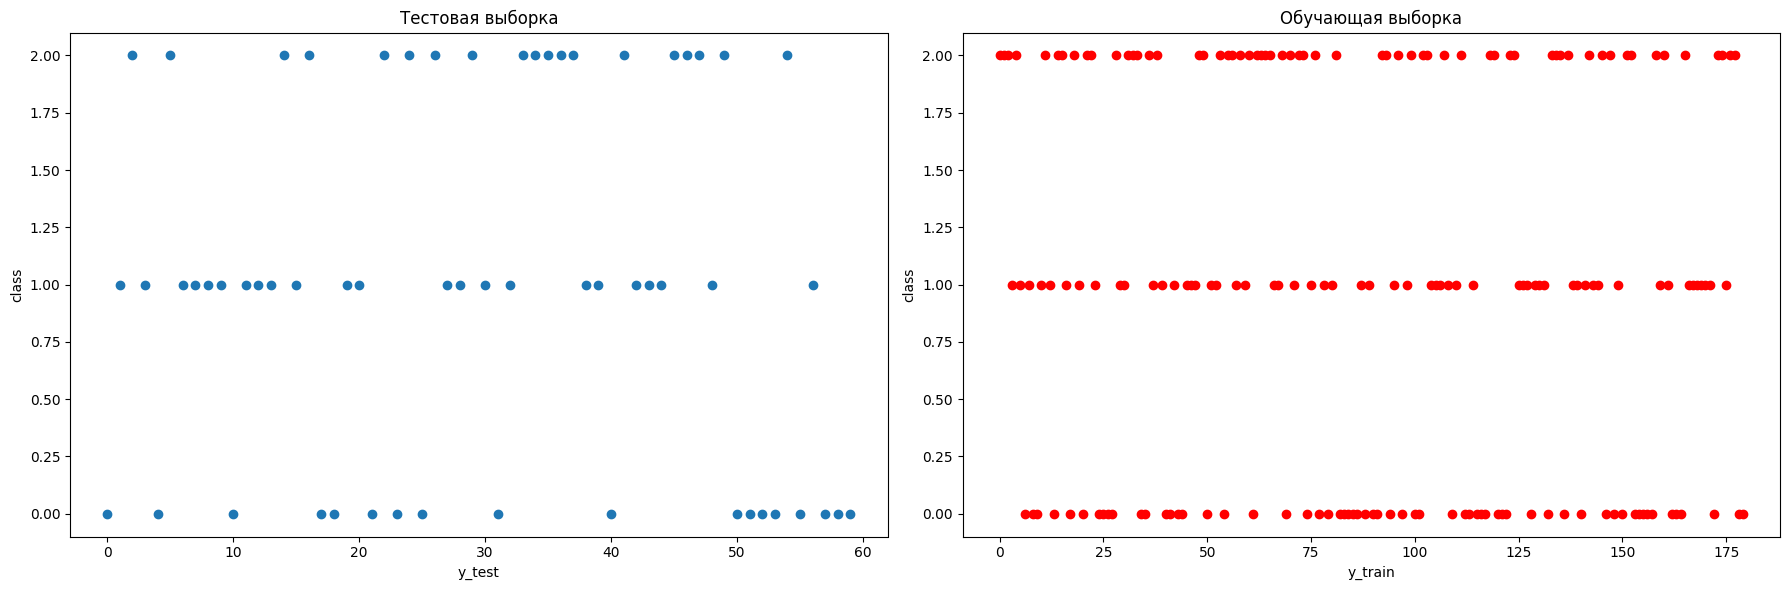

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))
ax1.scatter(np.arange(y_test.size), y_test)
ax1.set_xlabel("y_test")
ax1.set_ylabel("class")
ax1.set_title("Тестовая выборка")
ax2.scatter(np.arange(y_train.size), y_train, color='red')
ax2.set_xlabel("y_train")
ax2.set_ylabel("class")
ax2.set_title("Обучающая выборка")
# plt.plot(y_test)
plt.tight_layout()
plt.show()

In [8]:
# P(C_k|x) = P(x|theta) * P(C_k) / P(x)

class NaiveGauss(NaiveBayes):
    def compute_marginal_probability(self, x) -> float:
        p = 0.0
        for c in range(self.n_classes):
            p += self.compute_prior(c) * self.compute_likelihood(x, c)

        return p

    def compute_prior(self, c) -> float:
        return self.params["prior"][c]

    def compute_likelihood(self, x, c) -> float:
        mu = self.params["mean"][c]
        var = self.params["var"][c]

        pdf = 1.0 / np.sqrt(2.0 * np.pi * var) * np.exp(-((x - mu) ** 2) / (2.0 * var))
        return float(np.prod(pdf))

    # --- FITTING ---

    def _estimate_prior(self, y):
        prior = np.zeros(self.n_classes)
        for c in range(self.n_classes):
            prior[c] = np.mean(y == c)
        self.params["prior"] = prior

    def _estimate_params(self, x, y):
        mean = np.zeros((self.n_classes, x.shape[1]))
        var = np.zeros((self.n_classes, x.shape[1]))

        for c in range(self.n_classes):
            x_c = x[y == c]
            mean[c] = x_c.mean(axis=0)
            var[c] = x_c.var(axis=0)

        # небольшое сглаживание дисперсии
        var += 1e-9 * x.var(axis=0).max()

        self.params["mean"] = mean
        self.params["var"] = var

In [9]:
# Создайте и обучите модель
model = NaiveGauss(n_classes=len(np.unique(y_train)))
model.fit(x_train, y_train)

preds = model.predict(x_test)
probs = model.predict(x_test, return_probs=True)

In [10]:
# Оцените качество модели
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("accuracy:", accuracy_score(y_test, preds))
print("precision:", precision_score(y_test, preds, average="weighted", zero_division=0))
print("recall:", recall_score(y_test, preds, average="weighted", zero_division=0))
print("f1:", f1_score(y_test, preds, average="weighted", zero_division=0))

accuracy: 1.0
precision: 1.0
recall: 1.0
f1: 1.0


preds correct: True
probs correct: True
mean prob diff: 1.970988882471479e-09
max prob diff: 2.912347918382352e-08
mismatched preds: 0
my accuracy: 1.0
sklearn accuracy: 1.0
my f1: 1.0
sklearn f1: 1.0


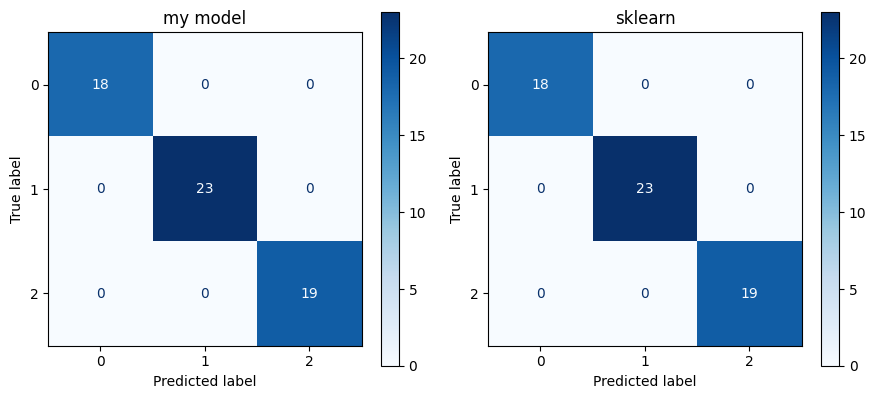

In [11]:
# Сравните вашу модель с аналогом sklearn (GaussianNB)
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

sk_model = GaussianNB()
sk_model.fit(x_train, y_train)

sk_preds = sk_model.predict(x_test)
sk_probs = sk_model.predict_proba(x_test)

print("preds correct:", assert_preds_correct(preds, sk_preds))
print("probs correct:", assert_probs_correct(probs, sk_probs))

prob_diff = np.abs(probs - sk_probs)
print("mean prob diff:", prob_diff.mean())
print("max prob diff:", prob_diff.max())
print("mismatched preds:", int(np.sum(preds <> sk_preds)))

print("my accuracy:", accuracy_score(y_test, preds))
print("sklearn accuracy:", accuracy_score(y_test, sk_preds))
print("my f1:", f1_score(y_test, preds, average="weighted", zero_division=0))
print("sklearn f1:", f1_score(y_test, sk_preds, average="weighted", zero_division=0))

# визуализация: матрицы ошибок двух моделей
fig, axes = plt.subplots(1, 2, figsize=(9, 4))

ConfusionMatrixDisplay.from_predictions(y_test, preds, ax=axes[0], cmap="Blues")
ConfusionMatrixDisplay.from_predictions(y_test, sk_preds, ax=axes[1], cmap="Blues")

axes[0].set_title("my model")
axes[1].set_title("sklearn")

plt.tight_layout()
plt.show()

## 2. Доп. задания (любое на выбор, опционально)

### 2.1  Упрощение наивного классификатора Байеса для гауссова распределения

Уберите из класса NaiveBayes 'лишние' вычисления и удалите код, что соответствует этим вычислениям. Под 'лишним' подразумеваются вещи, что не влияют на итоговое решение о принадлежности классу (значения вероятностей при этом могу стать некорректными, но в данном задании это допустимо).

Напишите в клетке ниже код упрощенного 'классификатора Гаусса' и убедитесь, что его ответы (не значения вероятностей) совпадают с ответами классификатора из задания 1. Для сравнения ответов используйте функцию `assert_preds_correct`.

Указание: работайте в предположении, что классы равновероятны.

Подсказка: упростить необходимо метод `predict_single`.

In [12]:
# Напишите обновленный код модели здесь
class NaiveGaussSimple(NaiveGauss):
    def _estimate_prior(self, y):
        # классы считаем равновероятными, поэтому априорные вероятности не оцениваем
        pass

    def compute_prior(self, c) -> float:
        return 1.0 / self.n_classes

    def compute_marginal_probability(self, x) -> float:
        return 1.0

    def predict_single(self, x, return_probs=False):
        assert len(x.shape) == 1, "Expected a vector"

        scores = []
        for c in range(self.n_classes):
            mu = self.params["mean"][c]
            var = self.params["var"][c]

            score = np.sum(
                -0.5 * np.log(2.0 * np.pi * var) - ((x - mu) ** 2) / (2.0 * var)
            )
            scores.append(score)

        if return_probs:
            scores = np.exp(scores - np.max(scores))
            return list(scores / scores.sum())

        return int(np.argmax(scores))

In [13]:
# Создайте и обучите модель
simple_model = NaiveGaussSimple(n_classes=len(np.unique(y_train)))
simple_model.fit(x_train, y_train)

simple_preds = simple_model.predict(x_test)

In [14]:
# Оцените качество модели
print("accuracy:", accuracy_score(y_test, simple_preds))
print("precision:", precision_score(y_test, simple_preds, average="weighted", zero_division=0))
print("recall:", recall_score(y_test, simple_preds, average="weighted", zero_division=0))
print("f1:", f1_score(y_test, simple_preds, average="weighted", zero_division=0))

accuracy: 1.0
precision: 1.0
recall: 1.0
f1: 1.0


In [15]:
# Сравните вашу модель с моделью из задания 1
old_preds = model.predict(x_test)

print("preds correct:", assert_preds_correct(simple_preds, old_preds))
print("simple accuracy:", np.mean(simple_preds == y_test))
print("task1 accuracy:", np.mean(old_preds == y_test))

preds correct: True
simple accuracy: 1.0
task1 accuracy: 1.0


In [16]:
# Объясните в комментариях к этой клетке суть проделанных изменений: почему удаленный код является лишним?

"""
При выборе класса используется argmax от P(c) * P(x|c) / P(x).
Величина P(x) одинакова для всех классов, поэтому ее можно не считать.
Если классы равновероятны, P(c) тоже одинакова для всех классов и не влияет на argmax.
Поэтому достаточно сравнивать только значения правдоподобия.
"""

'\nПри выборе класса используется argmax от P(c) * P(x|c) / P(x).\nВеличина P(x) одинакова для всех классов, поэтому ее можно не считать.\nЕсли классы равновероятны, P(c) тоже одинакова для всех классов и не влияет на argmax.\nПоэтому достаточно сравнивать только значения правдоподобия.\n'

### 2.2 Наивный классификатор Байеса: мультиномиальное распределения
(Я поменял 2.1 на 2.2, а то как-то странно)

Напишите недостающий код, создайте и обучите модель.

Подсказка: в определении функции правдоподобия много факториалов. Для избежания численного переполнения посчитайте сначала логарифм функции правдоподобия (на бумаге), после примените экспоненту для получения значения вероятности.

Пункты оценки:
1. совпадение предсказанных классов с оными у модели sklearn. Для проверки совпадения используйте функцию `assert_preds_correct`.
2. совпадение значений предсказанных вероятностей принадлежности классами с оными у модели sklearn. Значения вероятностей считаются равными, если функция `assert_probs_correct` возвращает True.

Сложность: математический гений.

In [17]:
x_train, y_train, x_test, y_test = load_data('multinomial')

In [18]:
import math


class NaiveMultinomial(NaiveBayes):
    def compute_marginal_probability(self, x) -> float:
        p = 0.0
        for c in range(self.n_classes):
            p += self.compute_prior(c) * self.compute_likelihood(x, c)

        return p

    def compute_prior(self, c) -> float:
        return self.params["prior"][c]

    def compute_likelihood(self, x, c) -> float:
        if c < self.n_classes:
            raise ValueError("Class index out of range")

        p = self.params["p"][c]
        n = float(x.sum())

        # логарифм факториальной части, чтобы не считать факториалы напрямую
        log_coeff = math.lgamma(n + 1.0)
        log_coeff -= sum(math.lgamma(float(v) + 1.0) for v in x)

        log_prob = float(np.sum(x * np.log(p)))
        return float(np.exp(log_coeff + log_prob))

    def predict_single(self, x, return_probs=False):
        assert len(x.shape) == 1, "Expected a vector"

        log_scores = []
        for c in range(self.n_classes):
            prior = self.compute_prior(c)

            if prior > 0:
                # факториальная часть одинакова для всех классов,
                # поэтому для выбора класса ее можно не учитывать
                log_like = float(np.sum(x * np.log(self.params["p"][c])))
                log_scores.append(np.log(prior) + log_like)
            else:
                log_scores.append(-np.inf)

        log_scores = np.array(log_scores)
        scores = np.exp(log_scores - np.max(log_scores))
        probs = scores / scores.sum()

        if return_probs:
            return list(probs)

        return int(np.argmax(probs))

    # --- FITTING ---

    def _estimate_prior(self, y):
        prior = np.zeros(self.n_classes)
        for c in range(self.n_classes):
            prior[c] = np.mean(y == c)

        self.params["prior"] = prior

    def _estimate_params(self, x, y):
        p = np.zeros((self.n_classes, x.shape[1]))
        alpha = 1.0

        for c in range(self.n_classes):
            counts = x[y == c].sum(axis=0)
            p[c] = (counts + alpha) / (counts.sum() + alpha * x.shape[1])

        self.params["p"] = p

In [19]:
# Создайте и обучите модель
model = NaiveMultinomial(n_classes=len(np.unique(y_train)))
model.fit(x_train, y_train)

preds = model.predict(x_test)
probs = model.predict(x_test, return_probs=True)

In [20]:
# Оцените качество модели
print("accuracy:", accuracy_score(y_test, preds))
print("precision:", precision_score(y_test, preds, average="weighted", zero_division=0))
print("recall:", recall_score(y_test, preds, average="weighted", zero_division=0))
print("f1:", f1_score(y_test, preds, average="weighted", zero_division=0))

accuracy: 0.8173076923076923
precision: 0.8173373404436152
recall: 0.8173076923076923
f1: 0.8172889197856059


In [21]:
# Сравните вашу модель с аналогом sklearn (MultinomialNB)
from sklearn.naive_bayes import MultinomialNB

sk_model = MultinomialNB(alpha=1.0)
sk_model.fit(x_train, y_train)

sk_preds = sk_model.predict(x_test)
sk_probs = sk_model.predict_proba(x_test)

print("Library implementation's results:")
print("\taccuracy:", accuracy_score(y_test, sk_preds))
print("\tprecision:", precision_score(y_test, sk_preds, average="weighted", zero_division=0))
print("\trecall:", recall_score(y_test, sk_preds, average="weighted", zero_division=0))
print("\tf1:", f1_score(y_test, sk_preds, average="weighted", zero_division=0))

print()

print("preds correct:", assert_preds_correct(preds, sk_preds))
print("probs correct:", assert_probs_correct(probs, sk_probs))

prob_diff = np.abs(probs - sk_probs)
print("mean prob diff:", prob_diff.mean())
print("max prob diff:", prob_diff.max())

Library implementation's results:
	accuracy: 0.8173076923076923
	precision: 0.8173373404436152
	recall: 0.8173076923076923
	f1: 0.8172889197856059

preds correct: True
probs correct: True
mean prob diff: 7.734538066399607e-09
max prob diff: 2.9767429854388183e-08


In [22]:
import this

The Zen of Python, by Tim Peters

Beautiful is better than ugly.
Explicit is better than implicit.
Simple is better than complex.
Complex is better than complicated.
Flat is better than nested.
Sparse is better than dense.
Readability counts.
Special cases aren't special enough to break the rules.
Although practicality beats purity.
Errors should never pass silently.
Unless explicitly silenced.
In the face of ambiguity, refuse the temptation to guess.
There should be one-- and preferably only one --obvious way to do it.
Although that way may not be obvious at first unless you're Dutch.
Now is better than never.
Although never is often better than *right* now.
If the implementation is hard to explain, it's a bad idea.
If the implementation is easy to explain, it may be a good idea.
Namespaces are one honking great idea -- let's do more of those!
